# Laboratorio #4 — Análisis Exploratorio de Datos (EDA)
**Universidad Técnica Nacional** · Minería de Datos (ISW-911) · III Cuatrimestre 2026

**Integrantes:**
- Nayely Vega
- Xavier Fernández
- Álvaro Víctor
- Maikel Chaves

**Conjunto de datos:** Estadísticas policiales del OIJ, año 2025.
Cada fila es un delito reportado en Costa Rica, con su tipo, fecha, hora, víctima y ubicación.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [5]:
URL = "https://raw.githubusercontent.com/xaviferzun/lab4-mineria/main/data/estadisticas_oij_2025.csv"

# Nombres correctos de las 12 columnas (al encabezado original le falta "Hora")
COLUMNAS = ["Delito", "SubDelito", "Fecha", "Hora", "Victima", "SubVictima",
            "Edad", "Sexo", "Nacionalidad", "Provincia", "Canton", "Distrito"]

def unir_nacionalidad(campos):
    # La fila llega con 13 campos: se juntan otra vez los campos 9 y 10 (la nacionalidad partida)
    return campos[:8] + [campos[8] + "," + campos[9]] + campos[10:]

df = pd.read_csv(URL, header=0, names=COLUMNAS,
                 engine="python", on_bad_lines=unir_nacionalidad)

print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (41071, 12)


,Delito,SubDelito,Fecha,Hora,Victima,SubVictima,Edad,Sexo,Nacionalidad,Provincia,Canton,Distrito
0,ASALTO,ARMA BLANCA,2025-01-03,18:00:00 - 20:59:59,VEHICULO,SERVICIO PUBLICO/TAXI LEGAL O PIRATA/AUTOBUS [...,Mayor de edad,HOMBRE,NICARAGUA,SAN JOSE,SAN JOSE,NaN
1,ASALTO,ARMA BLANCA,2025-01-08,06:00:00 - 08:59:59,PERSONA,PEATON [PERSONA],Mayor de edad,MUJER,COSTA RICA,ALAJUELA,ALAJUELA,NaN
2,ASALTO,ARMA BLANCA,2025-01-10,00:00:00 - 02:59:59,PERSONA,PEATON [PERSONA],Mayor de edad,HOMBRE,COSTA RICA,GUANACASTE,CANAS,NaN
3,ASALTO,ARMA BLANCA,2025-01-04,21:00:00 - 23:59:59,PERSONA,PEATON [PERSONA],Mayor de edad,HOMBRE,COSTA RICA,SAN JOSE,GOICOECHEA,NaN
4,ASALTO,ARMA BLANCA,2025-01-10,21:00:00 - 23:59:59,PERSONA,PEATON [PERSONA],Mayor de edad,HOMBRE,NICARAGUA,ALAJUELA,SAN CARLOS,NaN


## 1. Lectura del conjunto de datos desde GitHub (puntos 2 y 3)

El archivo se lee desde la URL *raw* del repositorio público.

**Problemas encontrados al leer el archivo original:**
1. **Comas dentro de un valor:** 4 filas tienen nacionalidades con coma (por ejemplo, `VIRGENES BRITANICAS, ISLAS`), por lo que pandas encuentra 13 columnas en lugar de 12 y da error.
   **Solución:** la función `unir_nacionalidad` vuelve a juntar esos dos campos.
2. **Encabezado incompleto:** al encabezado le falta la columna de la hora, por lo que todos los nombres quedaban corridos un lugar.
   **Solución:** se reemplaza el encabezado con la lista `COLUMNAS`.

Resultado: **41 071 registros y 12 columnas**.

## 2. Características principales del conjunto de datos (punto 4)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41071 entries, 0 to 41070
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Delito        41071 non-null  str    
 1   SubDelito     41071 non-null  str    
 2   Fecha         41071 non-null  str    
 3   Hora          41071 non-null  str    
 4   Victima       41071 non-null  str    
 5   SubVictima    41071 non-null  str    
 6   Edad          41071 non-null  str    
 7   Sexo          41071 non-null  str    
 8   Nacionalidad  41071 non-null  str    
 9   Provincia     41071 non-null  str    
 10  Canton        41071 non-null  str    
 11  Distrito      0 non-null      float64
dtypes: float64(1), str(11)
memory usage: 3.8 MB


**Observaciones de `info()`:**
- El dataset tiene 41 071 registros y 12 columnas.
- 11 columnas son de texto; ninguna variable es numérica.
- `Fecha` se leyó como texto; se convertirá a tipo fecha en el punto 9.
- `Distrito` está completamente vacía (0 valores no nulos); se trata en el punto 6.

In [8]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Delito,41071,6,HURTO,13553,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SubDelito,41071,39,POR DESCUIDO,7578,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fecha,41071,365,2025-11-01,191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hora,41071,8,00:00:00 - 02:59:59,7962,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Victima,41071,5,PERSONA,16593,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SubVictima,41071,87,PEATON [PERSONA],10011,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Edad,41071,4,Mayor de edad,34195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sexo,41071,3,HOMBRE,25386,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nacionalidad,41071,82,COSTA RICA,31763,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Provincia,41071,8,SAN JOSE,16126,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Observaciones de `describe()`:** el delito más frecuente es el **HURTO**, la víctima más común es la **PERSONA** y la provincia con más casos es **SAN JOSE**. Todos los delitos ocurrieron en 2025.

In [9]:
df.nunique().sort_values()

Distrito          0
Sexo              3
Edad              4
Victima           5
Delito            6
Hora              8
Provincia         8
SubDelito        39
Nacionalidad     82
Canton           85
SubVictima       87
Fecha           365
dtype: int64

In [10]:
for columna in ["Delito", "Victima", "Edad", "Sexo", "Provincia", "Hora"]:
    print(f"--- {columna} ---")
    print(df[columna].value_counts(), "\n")

--- Delito ---
Delito
HURTO                13553
ASALTO                9584
ROBO                  7559
ROBO DE VEHICULO      5155
TACHA DE VEHICULO     4350
HOMICIDIO              870
Name: count, dtype: int64 

--- Victima ---
Victima
PERSONA        16593
VEHICULO       11375
VIVIENDA        6675
EDIFICACION     4627
OTROS           1801
Name: count, dtype: int64 

--- Edad ---
Edad
Mayor de edad    34195
Adulto Mayor      3054
Desconocido       2861
Menor de edad      961
Name: count, dtype: int64 

--- Sexo ---
Sexo
HOMBRE         25386
MUJER          13225
DESCONOCIDO     2460
Name: count, dtype: int64 

--- Provincia ---
Provincia
SAN JOSE       16126
ALAJUELA        6365
PUNTARENAS      5044
GUANACASTE      3705
LIMON           3582
HEREDIA         3319
CARTAGO         2927
DESCONOCIDO        3
Name: count, dtype: int64 

--- Hora ---
Hora
00:00:00 - 02:59:59    7962
18:00:00 - 20:59:59    6558
15:00:00 - 17:59:59    5432
21:00:00 - 23:59:59    5353
12:00:00 - 14:59:59    4968
09

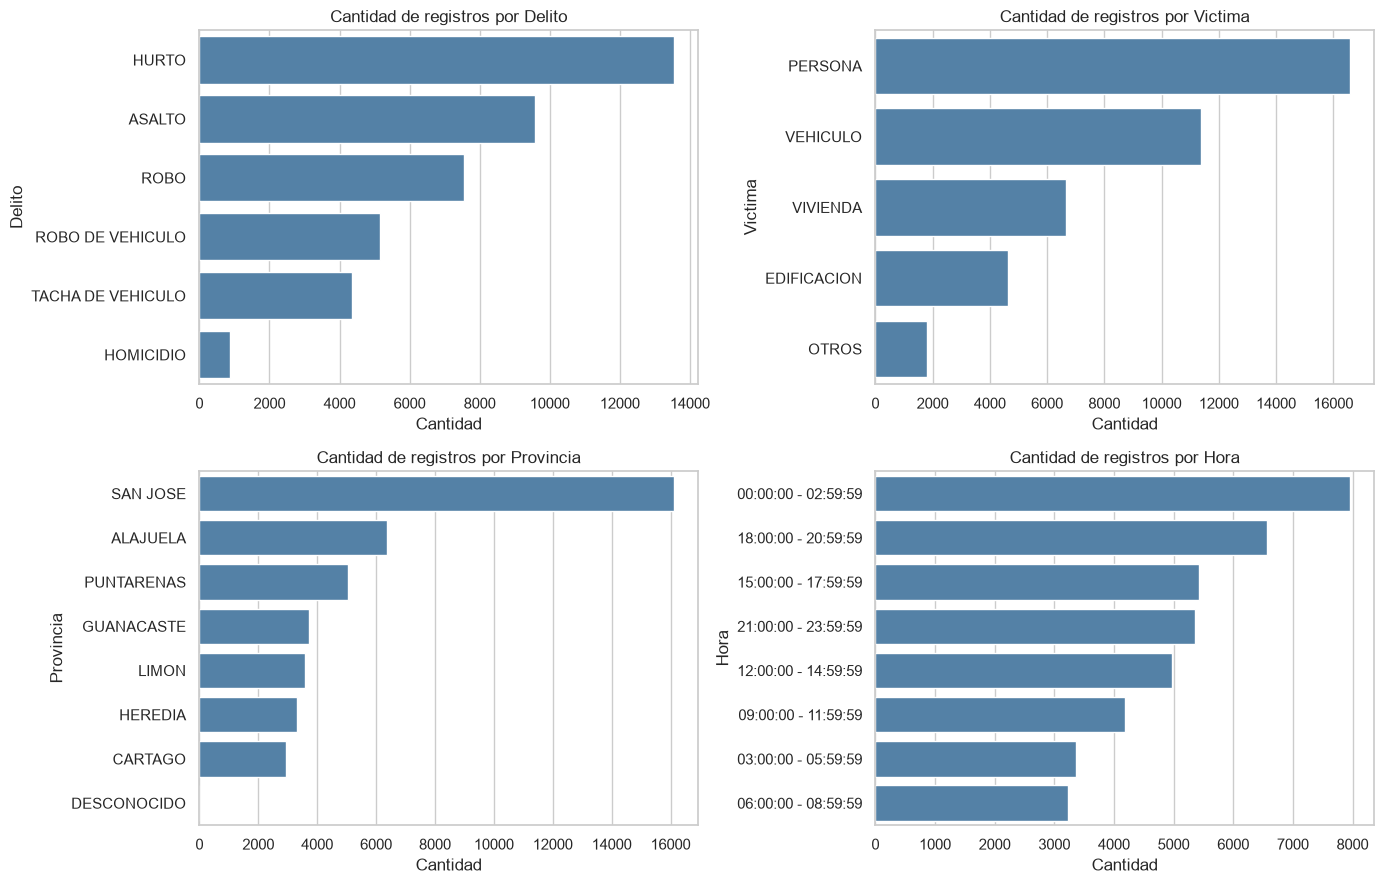

In [11]:
fig, ejes = plt.subplots(2, 2, figsize=(14, 9))
for eje, columna in zip(ejes.flat, ["Delito", "Victima", "Provincia", "Hora"]):
    orden = df[columna].value_counts().index
    sns.countplot(data=df, y=columna, order=orden, ax=eje, color="steelblue")
    eje.set_title(f"Cantidad de registros por {columna}")
    eje.set_xlabel("Cantidad")
plt.tight_layout()
plt.show()

**Observaciones de las variables categóricas:**
- Hay **6 categorías de delito**: el hurto es el más frecuente (13 553) y el homicidio el menos frecuente (870). Las clases están **desbalanceadas**.
- La víctima más común es la persona, seguida del vehículo.
- **San José** concentra cerca del 40 % de los registros.
- La franja horaria con más delitos es la de **00:00 a 02:59**.
- Hay valores **"Desconocido"** en Edad, Sexo, Nacionalidad y Provincia: funcionan como datos faltantes y se tratan en el punto 6.

In [12]:
print("Filas duplicadas:", df.duplicated().sum())

Filas duplicadas: 2812


## 3. Nombres de las columnas en español (punto 5)

Los nombres originales venían desalineados, sin tildes y sin un formato uniforme. Se renombran con nombres descriptivos en español, en minúscula y sin espacios.

In [13]:
NOMBRES_ES = {
    "Delito": "delito",
    "SubDelito": "subdelito",
    "Fecha": "fecha",
    "Hora": "rango_hora",
    "Victima": "tipo_victima",
    "SubVictima": "subtipo_victima",
    "Edad": "grupo_edad",
    "Sexo": "sexo",
    "Nacionalidad": "nacionalidad",
    "Provincia": "provincia",
    "Canton": "canton",
    "Distrito": "distrito",
}
df = df.rename(columns=NOMBRES_ES)
df.columns.tolist()

['delito',
 'subdelito',
 'fecha',
 'rango_hora',
 'tipo_victima',
 'subtipo_victima',
 'grupo_edad',
 'sexo',
 'nacionalidad',
 'provincia',
 'canton',
 'distrito']